In [1]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

Found 19159 files belonging to 5 classes.
Using 11496 files for training.


2025-03-31 16:03:15.594367: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-03-31 16:03:15.594416: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-31 16:03:15.594431: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-31 16:03:15.594465: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-31 16:03:15.594505: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30


2025-03-31 16:03:19.681839: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


360/360 ━━━━━━━━━━━━━━━━━━━━ 56s 135ms/step - accuracy: 0.4518 - loss: 2.3010 - val_accuracy: 0.7880 - val_loss: 0.6426 - learning_rate: 0.0010
Epoch 2/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 45s 126ms/step - accuracy: 0.6743 - loss: 1.0891 - val_accuracy: 0.8062 - val_loss: 0.5620 - learning_rate: 0.0010
Epoch 3/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 46s 126ms/step - accuracy: 0.7301 - loss: 0.7842 - val_accuracy: 0.8310 - val_loss: 0.4795 - learning_rate: 0.0010
Epoch 4/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 45s 125ms/step - accuracy: 0.7590 - loss: 0.6613 - val_accuracy: 0.8286 - val_loss: 0.4886 - learning_rate: 0.0010
Epoch 5/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 46s 128ms/step - accuracy: 0.7698 - loss: 0.6263 - val_accuracy: 0.8404 - val_loss: 0.4501 - learning_rate: 0.0010
Epoch 6/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 46s 129ms/step - accuracy: 0.7787 - loss: 0.6104 - val_accuracy: 0.8203 - val_loss: 0.4921 - learning_rate: 0.0010
Epoch 7/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 47s 130ms/step - accuracy: 0.7780 - loss:

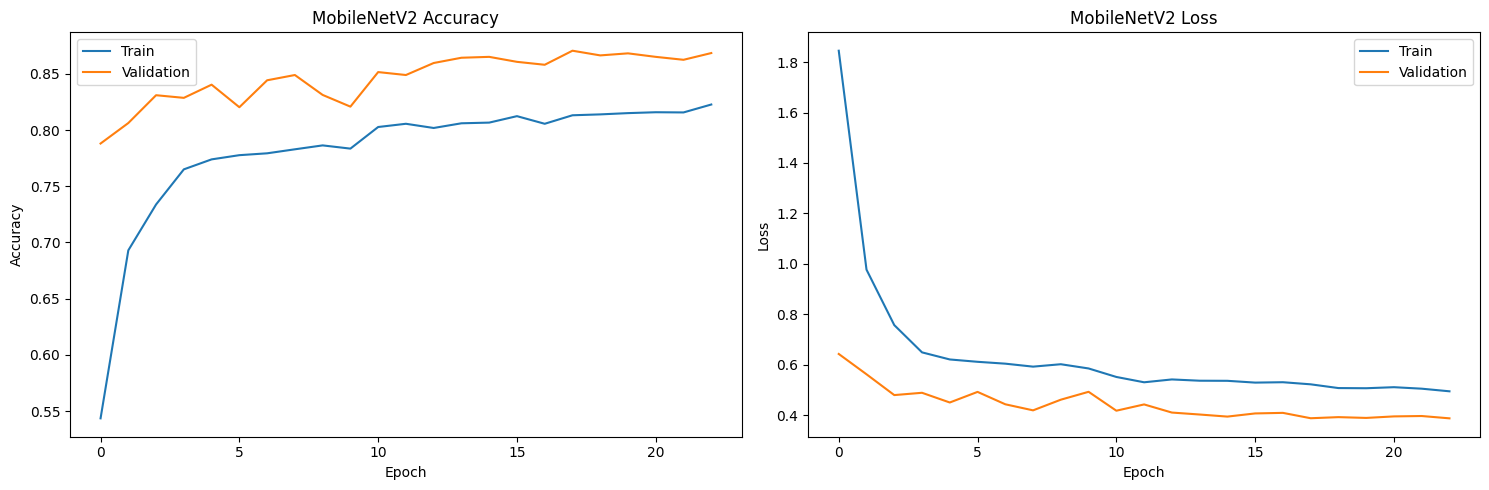

In [ ]:
# === 1. Setup ===
dataset_path = "../../../wheat_256px-dataset"
img_size = (224, 224)  # MobileNet's preferred input size
batch_size = 32
num_classes = 5
seed = 42

# === 2. Load and split dataset ===
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="training",
    seed=seed
)

val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="validation",
    seed=seed
)

val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

# === 3. Data Augmentation ===
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.15),
    RandomZoom(0.15),
    layers.RandomContrast(0.1),
])

# === 4. Load MobileNetV2 with proper preprocessing ===
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    alpha=1.0 
)
base_model.trainable = False  # Freeze initially

# === 5. Build Model ===
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x) 
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# === 6. Compile with MobileNet-optimized settings ===
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === 7. Enhanced Callbacks ===
callbacks = [
    EarlyStopping(patience=5, monitor='val_accuracy', restore_best_weights=True),
    ModelCheckpoint('mobilenet_best.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

# === 8. Training ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks
)

# === 9. Evaluation ===
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\nTest accuracy: {test_acc:.2%}")

# === 10. Enhanced Visualization ===
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()
